In [22]:
# 1️ Importer les bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer  # ✅ Ajout de l'import manquant
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold


In [23]:
# 2️ Charger le dataset
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)



Saving dataset_phishing.csv to dataset_phishing (1).csv


In [24]:
# 3 Informations
print("=== Aperçu ===")
print(df.head())
print("\n=== Infos ===")
print(df.info())
print("\n=== Statistiques ===")
print(df.describe())
print("\n=== Dimensions ===", df.shape)

=== Aperçu ===
                                                 url  length_url  \
0              http://www.crestonwood.com/router.php          37   
1  http://shadetreetechnology.com/V4/validation/a...          77   
2  https://support-appleld.com.secureupdate.duila...         126   
3                                 http://rgipt.ac.in          18   
4  http://www.iracing.com/tracks/gateway-motorspo...          55   

   length_hostname  ip  nb_dots  nb_hyphens  nb_at  nb_qm  nb_and  nb_or  ...  \
0               19   0        3           0      0      0       0      0  ...   
1               23   1        1           0      0      0       0      0  ...   
2               50   1        4           1      0      1       2      0  ...   
3               11   0        2           0      0      0       0      0  ...   
4               15   0        2           2      0      0       0      0  ...   

   domain_in_title  domain_with_copyright  whois_registered_domain  \
0                0 

In [25]:
!pip install ydata-profiling

In [6]:
#  4 EDA avec ydata_profiling
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title="Rapport EDA", explorative=True)
profile.to_file("rapport_EDA.html")

print("✅ Rapport EDA généré : rapport_EDA.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 89/89 [00:02<00:00, 35.35it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Rapport EDA généré : rapport_EDA.html


In [7]:
from google.colab import files

files.download("rapport_EDA.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
# 5 Gestion des valeurs manquantes

print("=== Gestion des valeurs manquantes ===")

missing = df.isnull().sum()

if missing.sum() == 0:
    print("✅ Aucune valeur manquante")
else:
    print("⚠️ Valeurs manquantes détectées :")
    print(missing[missing > 0])

    import numpy as np
    import pandas as pd
    from sklearn.impute import SimpleImputer

    # Séparation des colonnes
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

    # Imputers
    imputer_num = SimpleImputer(strategy='median')
    imputer_cat = SimpleImputer(strategy='most_frequent')

    # Application avec conservation des colonnes
    df[num_cols] = pd.DataFrame(
        imputer_num.fit_transform(df[num_cols]),
        columns=num_cols,
        index=df.index
    )

    df[cat_cols] = pd.DataFrame(
        imputer_cat.fit_transform(df[cat_cols]),
        columns=cat_cols,
        index=df.index
    )

    print("✅ Valeurs manquantes traitées correctement")



=== Gestion des valeurs manquantes ===
✅ Aucune valeur manquante


In [27]:
# b Correction de domain_age
# Les valeurs négatives (ex: -1, -12) sont des valeurs sentinelles signifiant 'inconnu'.
# On les remplace par 0 (neutre) plutôt que de prendre leur valeur absolue,
# ce qui éviterait d'interpréter -12 comme 12 jours.
df['domain_age'] = df['domain_age'].apply(lambda x: x if x >= 0 else 0)
print(df['domain_age'].sample(10))


5746     7626
7153     7519
8813        0
4203        0
9173        0
5866     4003
7846     7295
6392     2756
11230       0
10499    4654
Name: domain_age, dtype: int64


In [28]:
# 6 Détection et traitement des outliers (IQR + Clipping)
# ⚠️ Note : ce traitement est effectué avant le split train/test
# pour simplifier le notebook. Pour une rigueur maximale,
# il devrait être fait après le split (fit sur train, apply sur test).

import pandas as pd
import numpy as np

stats_outliers = []
num_cols = df.select_dtypes(include=[np.number]).columns

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    nb_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    pct_outliers = (nb_outliers / len(df)) * 100
    if nb_outliers > 0:
        stats_outliers.append({
            'Colonne': col,
            'Nb Outliers': nb_outliers,
            'Taux (%)': round(pct_outliers, 2),
            'Borne Inf': lower,
            'Borne Sup': upper
        })

df_resume = pd.DataFrame(stats_outliers)

if not df_resume.empty:
    df_resume = df_resume.sort_values(by='Nb Outliers', ascending=False)
    print('📊 Résumé priorisé des colonnes avec valeurs aberrantes :')
    print(df_resume[['Colonne', 'Nb Outliers', 'Taux (%)']].to_string(index=False))
else:
    print('✅ Aucune valeur aberrante détectée.')

print('\n=== Traitement des outliers (Clipping) ===')
if not df_resume.empty:
    for _, row in df_resume.iterrows():
        col = row['Colonne']
        df[col] = df[col].clip(lower=row['Borne Inf'], upper=row['Borne Sup'])
    print(f"✅ Clipping terminé pour les {len(df_resume)} colonnes concernées.")
else:
    print('ℹ️ Rien à traiter.')


📊 Résumé priorisé des colonnes avec valeurs aberrantes :
                   Colonne  Nb Outliers  Taux (%)
           domain_in_title         2562     22.41
             prefix_suffix         2314     20.24
           ratio_extErrors         2149     18.80
               web_traffic         2138     18.71
               phish_hints         2041     17.86
            ratio_extMedia         2012     17.60
                        ip         1721     15.06
             nb_underscore         1695     14.83
                     nb_eq         1564     13.68
                     nb_qm         1555     13.60
domain_registration_length         1529     13.38
         ratio_digits_host         1503     13.15
        shortest_words_raw         1435     12.55
               empty_title         1426     12.48
        shortening_service         1411     12.34
                nb_hyphens         1371     11.99
                    nb_com         1327     11.61
           domain_in_brand         1191    

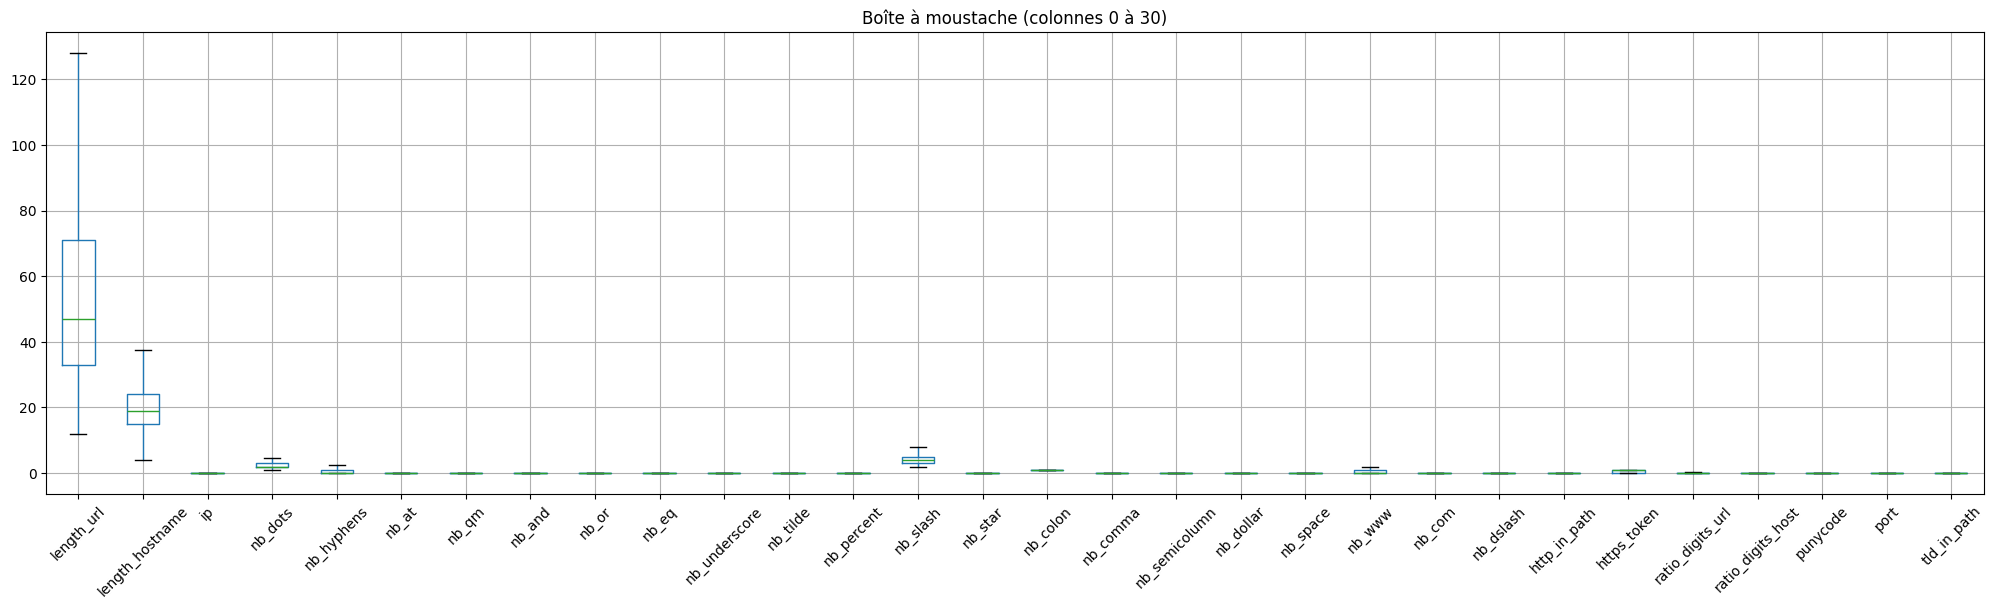

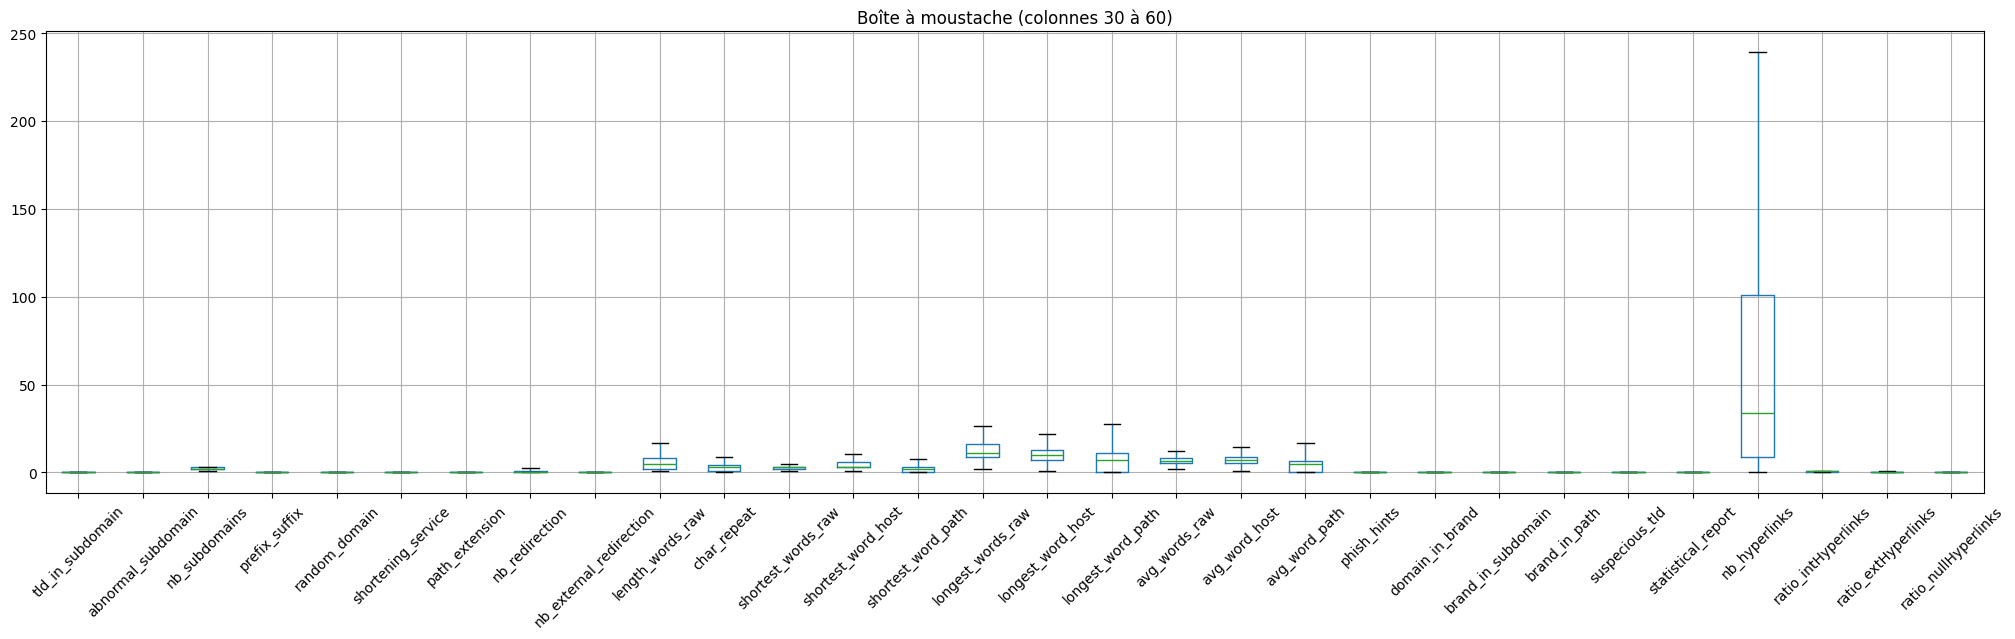

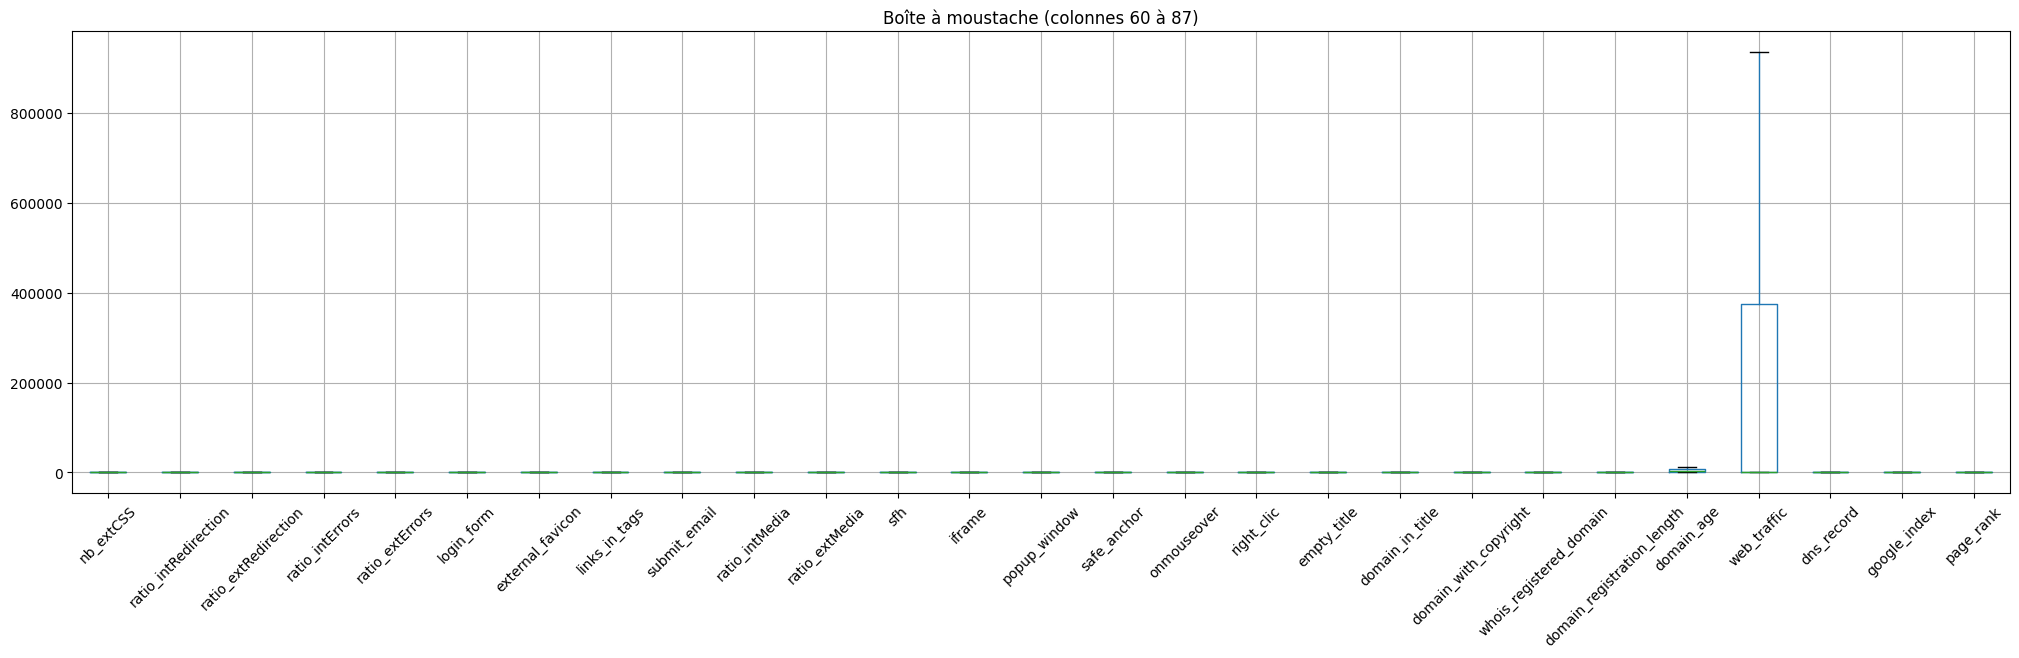

In [29]:
# b Visualisation des distributions après clipping (boîtes à moustaches)
import matplotlib.pyplot as plt

num_cols = df.select_dtypes(include=[np.number]).columns
chunk_size = 30

for i in range(0, len(num_cols), chunk_size):
    cols = num_cols[i:i+chunk_size]
    plt.figure(figsize=(25, 6))
    df[cols].boxplot()
    plt.xticks(rotation=45)
    plt.title(f'Boîte à moustache (colonnes {i} à {i+len(cols)})')
    plt.show()


In [30]:
# 7 Feature Engineering

# 5a. Encodage de la variable cible (target)
df['status'] = df['status'].astype(str).str.strip().str.lower()
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})
df = df.dropna(subset=['status'])
df['status'] = df['status'].astype(int)

print('Répartition des classes :')
print(df['status'].value_counts())

# 5b. Feature Engineering spécifique à la colonne URL
df['url_length'] = df['url'].apply(len)
# ✅ Correction : on vérifie que l'URL commence par 'https://' (plus précis)
df['has_https'] = df['url'].str.startswith('https://').astype(int)
df['num_digits'] = df['url'].str.count(r'\d')
df['num_special'] = df['url'].str.count(r'[!@#$%^&*(),.?":{}|<>]')

# 5c. Supprimer la colonne brute 'url'
df = df.drop(columns=['url'])



Répartition des classes :
status
0    5715
1    5715
Name: count, dtype: int64


In [31]:
# 8 Split Train/Test (TRÈS IMPORTANT : à faire avant toute sélection/suppression)
from sklearn.model_selection import train_test_split

# Séparer features (X) et target (y)
X = df.drop('status', axis=1)
y = df['status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train : {X_train.shape[0]} échantillons")
print(f"Test  : {X_test.shape[0]} échantillons")
print(f"Features avant traitement : {X_train.shape[1]}")

Train : 9144 échantillons
Test  : 2286 échantillons
Features avant traitement : 91


In [32]:
# 9 Suppression des colonnes trop corrélées - SUR TRAIN UNIQUEMENT
print("=== Suppression des features corrélées ===")

corr_matrix = X_train.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# 🔍 1. Identifier TOUTES les paires avec corrélation > 0.95
high_corr_pairs = []
for col in upper.columns:
    for row in upper.index:
        if upper.loc[row, col] > 0.95:
            high_corr_pairs.append((row, col, upper.loc[row, col]))

print(f"📊 Paires hautement corrélées (> 0.95) :")
for pair in high_corr_pairs:
    print(f"   - {pair[0]} ↔ {pair[1]} : {pair[2]:.3f}")

# 🎯 2. Décider stratégiquement quelle feature supprimer
# Stratégie : on garde celle avec la plus forte corrélation à la target (y_train)
# Calculer corrélation avec la target pour chaque feature
corr_with_target = X_train.corrwith(y_train).abs()

to_drop_corr = set()
for col1, col2, _ in high_corr_pairs:
    # Garder la feature la plus corrélée à la target
    if corr_with_target[col1] >= corr_with_target[col2]:
        to_drop_corr.add(col2)
        print(f"   → Suppression de '{col2}' (gardé '{col1}')")
    else:
        to_drop_corr.add(col1)
        print(f"   → Suppression de '{col1}' (gardé '{col2}')")

to_drop_corr = list(to_drop_corr)

print(f"\n✅ Features supprimées (après analyse) : {to_drop_corr}")

# 3. Supprimer sur TRAIN et TEST
X_train = X_train.drop(columns=to_drop_corr)
X_test = X_test.drop(columns=to_drop_corr)

print(f"✅ Features après suppression corrélations : {X_train.shape[1]}")

=== Suppression des features corrélées ===
📊 Paires hautement corrélées (> 0.95) :
   - https_token ↔ has_https : 1.000
   → Suppression de 'has_https' (gardé 'https_token')

✅ Features supprimées (après analyse) : ['has_https']
✅ Features après suppression corrélations : 90


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [33]:
# Après votre code actuel, ajoutez :
import numpy as np

# Masquer la diagonale
np.fill_diagonal(corr_matrix.values, 0)
max_corr = corr_matrix.max().max()
print(f"🔍 Corrélation maximale entre features : {max_corr:.3f}")

🔍 Corrélation maximale entre features : 1.000


In [64]:
# 11 Normalisation des features X
import joblib

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("✅ Normalisation effectuée sur les features")
print(f"Train shape : {X_train_scaled.shape}")
print(f"Test shape : {X_test_scaled.shape}")

# Sauvegarder le scaler
joblib.dump(scaler, 'scaler.pkl')
print("✅ Scaler sauvegardé dans 'scaler.pkl'")


✅ Normalisation effectuée sur les features
Train shape : (9144, 20)
Test shape : (2286, 20)
✅ Scaler sauvegardé dans 'scaler.pkl'


In [67]:
# 10 Suppression des features à faible variance - APRÈS NORMALISATION
print("=== Suppression des features à faible variance ===")

from sklearn.feature_selection import VarianceThreshold

# Vérifier l'état des données
print(f"🔍 Type de X_train : {type(X_train)}")
print(f"🔍 Type de X_train_scaled : {type(X_train_scaled)}")
print(f"🔍 X_train shape : {X_train.shape}")
print(f"🔍 X_train_scaled shape : {X_train_scaled.shape}")

# Appliquer VarianceThreshold
selector_var = VarianceThreshold(threshold=0.01)
X_train_scaled_var = selector_var.fit_transform(X_train_scaled)
X_test_scaled_var = selector_var.transform(X_test_scaled)

# Récupérer les noms des colonnes conservées (si possible)
try:
    # Cas 1: X_train est un DataFrame avec des colonnes
    if hasattr(X_train, 'columns') and X_train.shape[1] == X_train_scaled.shape[1]:
        cols_kept = X_train.columns[selector_var.get_support()].tolist()
        cols_dropped = [c for c in X_train.columns if c not in cols_kept]
        print(f"✅ Features conservées : {len(cols_kept)}")
        if cols_dropped:
            print(f"✅ Features supprimées (variance < 0.01) : {cols_dropped}")
    else:
        # Cas 2: X_train est un array ou les dimensions ne correspondent pas
        n_features_kept = selector_var.get_support().sum()
        n_features_total = X_train_scaled.shape[1]
        print(f"✅ Features conservées : {n_features_kept} / {n_features_total}")
        print(f"ℹ️  Impossible de lister les noms (X_train n'est pas un DataFrame avec les bonnes dimensions)")
except Exception as e:
    print(f"⚠️  Note: {e}")
    print(f"✅ Features conservées : {X_train_scaled_var.shape[1]}")

print(f"✅ Nouvelle forme Train : {X_train_scaled_var.shape}")
print(f"✅ Nouvelle forme Test : {X_test_scaled_var.shape}")

# Mettre à jour les variables (elles deviennent des arrays)
X_train_scaled = X_train_scaled_var
X_test_scaled = X_test_scaled_var

print(f"✅ Mise à jour terminée - X_train_scaled est maintenant un array de shape {X_train_scaled.shape}")

=== Suppression des features à faible variance ===
🔍 Type de X_train : <class 'numpy.ndarray'>
🔍 Type de X_train_scaled : <class 'numpy.ndarray'>
🔍 X_train shape : (9144, 20)
🔍 X_train_scaled shape : (9144, 20)
✅ Features conservées : 20 / 20
ℹ️  Impossible de lister les noms (X_train n'est pas un DataFrame avec les bonnes dimensions)
✅ Nouvelle forme Train : (9144, 20)
✅ Nouvelle forme Test : (2286, 20)
✅ Mise à jour terminée - X_train_scaled est maintenant un array de shape (9144, 20)


In [38]:
# 12 Feature Selection (SelectKBest) - FIT sur TRAIN uniquement
print("=== Feature Selection ===")

k = min(20, X_train_scaled.shape[1])
selector = SelectKBest(score_func=f_classif, k=k)
X_train_final = selector.fit_transform(X_train_scaled, y_train)
X_test_final = selector.transform(X_test_scaled)

# Récupérer les noms des features sélectionnées
selected_features = X_train.columns[selector.get_support()]
print(f"✅ Features sélectionnées (top {k}) :")
print(list(selected_features))
print(f"Shape final — Train : {X_train_final.shape} | Test : {X_test_final.shape}")

# Sauvegarder le selector
joblib.dump(selector, 'selector.pkl')
print("✅ Selector sauvegardé dans 'selector.pkl'")

=== Feature Selection ===
✅ Features sélectionnées (top 20) :
['length_url', 'length_hostname', 'nb_dots', 'nb_slash', 'nb_www', 'ratio_digits_url', 'length_words_raw', 'longest_words_raw', 'longest_word_path', 'avg_word_path', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_extErrors', 'domain_registration_length', 'domain_age', 'google_index', 'page_rank', 'url_length', 'num_digits', 'num_special']
Shape final — Train : (9144, 20) | Test : (2286, 20)
✅ Selector sauvegardé dans 'selector.pkl'


/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 2  5  6  7  8  9 10 11 12 14 15 16 17 18 19 21 22 23 26 27 28 29 30 31
 33 34 35 36 38 50 51 52 53 54 55 59 61 63 65 68 71 72 73 75 76 77 78 80
 84] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [39]:
# Vérification finale
print("=== Vérification finale ===")
print(f"✅ Train shape: {X_train_final.shape}")
print(f"✅ Test shape: {X_test_final.shape}")
print(f"✅ Train target shape: {y_train.shape}")
print(f"✅ Test target shape: {y_test.shape}")

# Vérification qu'il n'y a pas de data leakage
assert X_train_final.shape[0] == y_train.shape[0]
assert X_test_final.shape[0] == y_test.shape[0]
print("✅ Toutes les vérifications sont passées - Pas de data leakage détecté")

=== Vérification finale ===
✅ Train shape: (9144, 20)
✅ Test shape: (2286, 20)
✅ Train target shape: (9144,)
✅ Test target shape: (2286,)
✅ Toutes les vérifications sont passées - Pas de data leakage détecté


In [40]:
selected_features = [
'length_url', 'length_hostname', 'nb_dots', 'nb_slash', 'nb_www',
'length_words_raw', 'shortest_word_host', 'longest_words_raw',
'longest_word_path', 'avg_word_path', 'nb_hyperlinks',
'ratio_intHyperlinks', 'ratio_extRedirection',
'domain_registration_length', 'domain_age', 'google_index',
'page_rank', 'url_length', 'num_digits', 'num_special'
]

In [41]:
df_final = df[selected_features + ['status']]

In [42]:
print(df_final.shape)
print(df_final.head())

(11430, 21)
   length_url  length_hostname  nb_dots  nb_slash  nb_www  length_words_raw  \
0          37             19.0      3.0         3       1                 4   
1          77             23.0      1.0         5       0                 4   
2         126             37.5      4.0         5       0                12   
3          18             11.0      2.0         2       0                 1   
4          55             15.0      2.0         5       1                 6   

   shortest_word_host  longest_words_raw  longest_word_path  avg_word_path  \
0                 3.0               11.0                6.0       4.500000   
1                10.5               26.5               27.5      14.666667   
2                 3.0               17.0               17.0       8.142857   
3                 5.0                5.0                0.0       0.000000   
4                 3.0               11.0               11.0       7.000000   

   ...  ratio_intHyperlinks  ratio_extRedire

In [43]:
df_final.to_csv("df_final_20_features.csv", index=False)

from google.colab import files
files.download("df_final_20_features.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
df_final.info()
df_final.describe()
df_final['status'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   length_url                  11430 non-null  int64  
 1   length_hostname             11430 non-null  float64
 2   nb_dots                     11430 non-null  float64
 3   nb_slash                    11430 non-null  int64  
 4   nb_www                      11430 non-null  int64  
 5   length_words_raw            11430 non-null  int64  
 6   shortest_word_host          11430 non-null  float64
 7   longest_words_raw           11430 non-null  float64
 8   longest_word_path           11430 non-null  float64
 9   avg_word_path               11430 non-null  float64
 10  nb_hyperlinks               11430 non-null  int64  
 11  ratio_intHyperlinks         11430 non-null  float64
 12  ratio_extRedirection        11430 non-null  float64
 13  domain_registration_length  114

,count
status,
0,5715
1,5715


**KNN_SVM**

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score,
                              roc_auc_score, confusion_matrix,
                              classification_report, ConfusionMatrixDisplay)

In [46]:
from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)
print(df.shape)
print(df.head())

Saving Phishing.csv to Phishing (1).csv
(11430, 21)
   length_url  length_hostname  nb_dots  nb_slash  nb_www  length_words_raw  \
0          37             19.0      3.0         3       1                 4   
1          77             23.0      1.0         5       0                 4   
2         126             37.5      4.0         5       0                12   
3          18             11.0      2.0         2       0                 1   
4          55             15.0      2.0         5       1                 6   

   shortest_word_host  longest_words_raw  longest_word_path  avg_word_path  \
0                 3.0               11.0                6.0       4.500000   
1                10.5               26.5               27.5      14.666667   
2                 3.0               17.0               17.0       8.142857   
3                 5.0                5.0                0.0       0.000000   
4                 3.0               11.0               11.0       7.000000   

   .

## **KNN**

In [47]:
#import
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score,
                              roc_auc_score, confusion_matrix,
                              classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

In [48]:
X = df.drop('status', axis=1)
y = df['status']
print(f"Nombre de features : {X.shape[1]}")
print(f"Nombre d'échantillons : {X.shape[0]}")

Nombre de features : 20
Nombre d'échantillons : 11430


In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Train : {X_train.shape[0]} échantillons")
print(f"Test  : {X_test.shape[0]} échantillons")

Train : 9144 échantillons
Test  : 2286 échantillons


In [50]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("✅ Normalisation effectuée sur les features")

✅ Normalisation effectuée sur les features


In [51]:
# Entrainement KNN (k=5 par défaut)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
print('✅ Modèle KNN entraîné')

✅ Modèle KNN entraîné


In [52]:
y_pred_knn = knn.predict(X_test)
y_proba_knn = knn.predict_proba(X_test)[:, 1]

In [53]:
proba_df = pd.DataFrame({
    'P(Légitime)': knn.predict_proba(X_test)[:, 0],
    'P(Phishing)': knn.predict_proba(X_test)[:, 1]
})
proba_df['Prédiction'] = y_pred_knn
proba_df['Réel'] = y_test.values

print(proba_df.head(10))

   P(Légitime)  P(Phishing)  Prédiction  Réel
0          1.0          0.0           0     0
1          1.0          0.0           0     0
2          1.0          0.0           0     0
3          1.0          0.0           0     0
4          0.0          1.0           1     1
5          1.0          0.0           0     0
6          0.0          1.0           1     1
7          0.4          0.6           1     0
8          1.0          0.0           0     0
9          1.0          0.0           0     0


In [54]:
print('-' * 40)
print('      Résultats KNN')
print('-' * 40)
print(f'Accuracy  : {accuracy_score(y_test, y_pred_knn):.4f}')
print(f'Précision : {precision_score(y_test, y_pred_knn):.4f}')
print(f'Recall    : {recall_score(y_test, y_pred_knn):.4f}')
print(f'F1-score  : {f1_score(y_test, y_pred_knn):.4f}')
print(f'ROC-AUC   : {roc_auc_score(y_test, y_proba_knn):.4f}')
print()
print(classification_report(y_test, y_pred_knn,
      target_names=['Légitime', 'Phishing']))

----------------------------------------
      Résultats KNN
----------------------------------------
Accuracy  : 0.9484
Précision : 0.9469
Recall    : 0.9486
F1-score  : 0.9478
ROC-AUC   : 0.9807

              precision    recall  f1-score   support

    Légitime       0.95      0.95      0.95      1157
    Phishing       0.95      0.95      0.95      1129

    accuracy                           0.95      2286
   macro avg       0.95      0.95      0.95      2286
weighted avg       0.95      0.95      0.95      2286



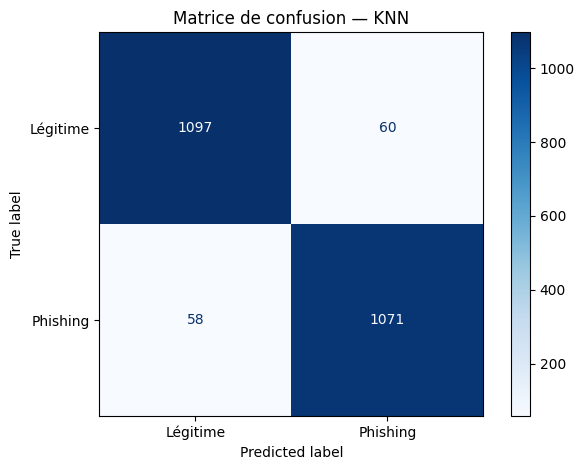

In [55]:
cm = confusion_matrix(y_test, y_pred_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['Légitime', 'Phishing'])
disp.plot(cmap='Blues')
plt.title('Matrice de confusion — KNN')
plt.tight_layout()
plt.show()

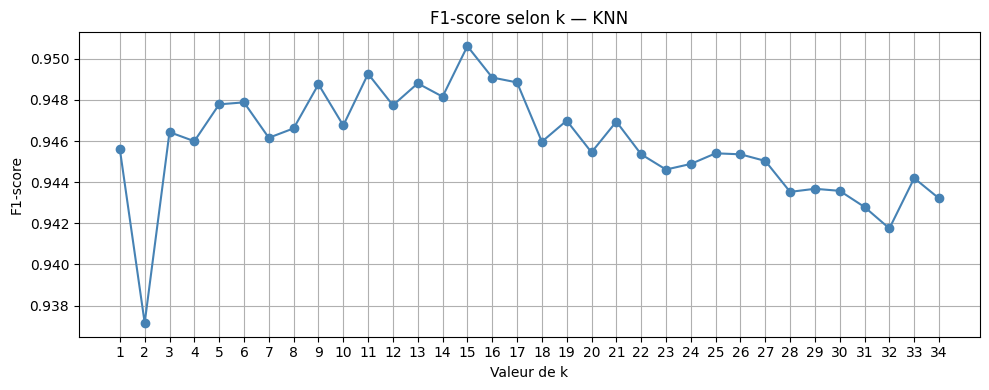

✅ Meilleur k : 15 avec F1-score = 0.9506


In [56]:
# Tester k de 1 à 34 et tracer l'évolution du F1-score
k_values = range(1, 35)
f1_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    f1_scores.append(f1_score(y_test, preds))

plt.figure(figsize=(10, 4))
plt.plot(k_values, f1_scores, marker='o', color='steelblue')
plt.xlabel('Valeur de k')
plt.ylabel('F1-score')
plt.title('F1-score selon k — KNN')
plt.xticks(k_values)
plt.grid(True)
plt.tight_layout()
plt.show()

best_k = k_values[f1_scores.index(max(f1_scores))]
print(f'✅ Meilleur k : {best_k} avec F1-score = {max(f1_scores):.4f}')

In [57]:
# Entrainement KNN (k=best_k)
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)
print('✅ Modèle KNN entraîné')

# Mettre à jour les prédictions avec best_k
y_pred_knn = knn.predict(X_test)
y_proba_knn = knn.predict_proba(X_test)[:, 1]

✅ Modèle KNN entraîné


In [58]:
print('-' * 40)
print('      Résultats KNN k=best_k')
print('-' * 40)
print(f'Accuracy  : {accuracy_score(y_test, y_pred_knn):.4f}')
print(f'Précision : {precision_score(y_test, y_pred_knn):.4f}')
print(f'Recall    : {recall_score(y_test, y_pred_knn):.4f}')
print(f'F1-score  : {f1_score(y_test, y_pred_knn):.4f}')
print(f'ROC-AUC   : {roc_auc_score(y_test, y_proba_knn):.4f}')
print()
print(classification_report(y_test, y_pred_knn,
      target_names=['Légitime', 'Phishing']))

----------------------------------------
      Résultats KNN k=best_k
----------------------------------------
Accuracy  : 0.9510
Précision : 0.9464
Recall    : 0.9548
F1-score  : 0.9506
ROC-AUC   : 0.9861

              precision    recall  f1-score   support

    Légitime       0.96      0.95      0.95      1157
    Phishing       0.95      0.95      0.95      1129

    accuracy                           0.95      2286
   macro avg       0.95      0.95      0.95      2286
weighted avg       0.95      0.95      0.95      2286



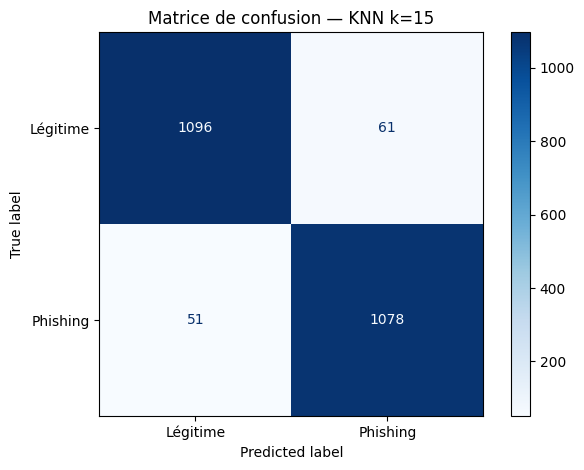

In [59]:
cm = confusion_matrix(y_test, y_pred_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['Légitime', 'Phishing'])
disp.plot(cmap='Blues')
plt.title(f'Matrice de confusion — KNN k={best_k}')
plt.tight_layout()
plt.show()

# **SVM**

In [60]:
from sklearn.svm import SVC

svm = SVC(probability=True, random_state=42)
svm.fit(X_train, y_train)
print('✅ Modèle SVM entraîné')

y_pred_svm = svm.predict(X_test)
y_proba_svm = svm.predict_proba(X_test)[:, 1]

✅ Modèle SVM entraîné


In [61]:
print('-' * 40)
print('      Résultats SVM')
print('-' * 40)
print(f'Accuracy  : {accuracy_score(y_test, y_pred_svm):.4f}')
print(f'Précision : {precision_score(y_test, y_pred_svm):.4f}')
print(f'Recall    : {recall_score(y_test, y_pred_svm):.4f}')
print(f'F1-score  : {f1_score(y_test, y_pred_svm):.4f}')
print(f'ROC-AUC   : {roc_auc_score(y_test, y_proba_svm):.4f}')
print()
print(classification_report(y_test, y_pred_svm,
      target_names=['Légitime', 'Phishing']))

----------------------------------------
      Résultats SVM
----------------------------------------
Accuracy  : 0.9580
Précision : 0.9543
Recall    : 0.9610
F1-score  : 0.9576
ROC-AUC   : 0.9901

              precision    recall  f1-score   support

    Légitime       0.96      0.96      0.96      1157
    Phishing       0.95      0.96      0.96      1129

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286



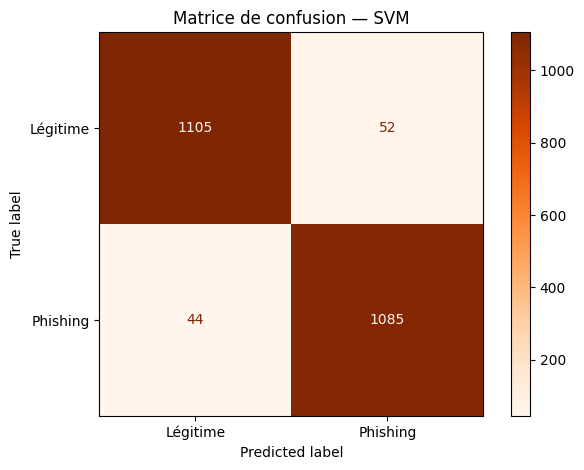

In [62]:
cm_svm = confusion_matrix(y_test, y_pred_svm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm,
                               display_labels=['Légitime', 'Phishing'])
disp.plot(cmap='Oranges')
plt.title('Matrice de confusion — SVM')
plt.tight_layout()
plt.show()

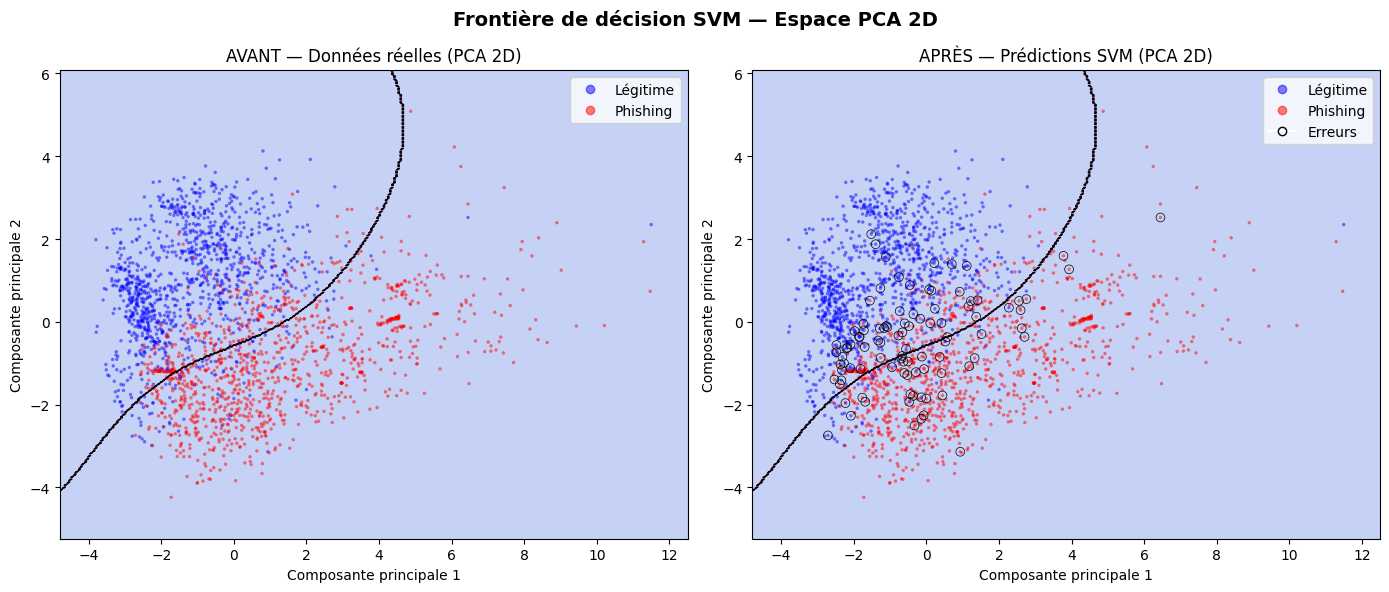

Variance expliquée par les 2 composantes : 43.0%


In [63]:
from sklearn.decomposition import PCA
import numpy as np

pca = PCA(n_components=2)
X_test_2d = pca.fit_transform(X_test)

x_min, x_max = X_test_2d[:, 0].min() - 1, X_test_2d[:, 0].max() + 1
y_min, y_max = X_test_2d[:, 1].min() - 1, X_test_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                      np.linspace(y_min, y_max, 300))

grid_2d = np.c_[xx.ravel(), yy.ravel()]
grid_3d = pca.inverse_transform(grid_2d)
Z = svm.predict(grid_3d).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].contourf(xx, yy, Z, alpha=0.3, colors=['#4169E1', '#DC143C'])
axes[0].contour(xx, yy, Z, colors='black', linewidths=0.5, linestyles='--')
scatter = axes[0].scatter(X_test_2d[:, 0], X_test_2d[:, 1],
                           c=y_test.values, cmap='bwr', alpha=0.5, s=6, edgecolors='none')
axes[0].set_title('AVANT — Données réelles (PCA 2D)')
axes[0].set_xlabel('Composante principale 1')
axes[0].set_ylabel('Composante principale 2')
axes[0].legend(handles=scatter.legend_elements()[0],
               labels=['Légitime', 'Phishing'], loc='upper right')

axes[1].contourf(xx, yy, Z, alpha=0.3, colors=['#4169E1', '#DC143C'])
axes[1].contour(xx, yy, Z, colors='black', linewidths=0.5, linestyles='--')
scatter2 = axes[1].scatter(X_test_2d[:, 0], X_test_2d[:, 1],
                            c=y_pred_svm, cmap='bwr', alpha=0.5, s=6, edgecolors='none')
errors = y_pred_svm != y_test.values
axes[1].scatter(X_test_2d[errors, 0], X_test_2d[errors, 1],
                s=40, facecolors='none', edgecolors='black', linewidths=0.5, label='Erreurs')
axes[1].set_title('APRÈS — Prédictions SVM (PCA 2D)')
axes[1].set_xlabel('Composante principale 1')
axes[1].set_ylabel('Composante principale 2')
axes[1].legend(handles=scatter2.legend_elements()[0] + [plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='none', markeredgecolor='black', markersize=6, label='Erreurs')],
               labels=['Légitime', 'Phishing', 'Erreurs'], loc='upper right')

plt.suptitle('Frontière de décision SVM — Espace PCA 2D',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('Variance expliquée par les 2 composantes : '
      f'{pca.explained_variance_ratio_.sum():.1%}')

## **Arbre de decision**

In [66]:
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')          # Pas d'affichage graphique (serveur)
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
)
import warnings
warnings.filterwarnings('ignore')


from google.colab import files

In [68]:
# 2️ Charger le dataset
uploaded = files.upload()
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

Saving Phishing.csv to Phishing (2).csv


In [69]:

# 1. CHARGEMENT & PRÉPARATION DES DONNÉES
print("=" * 60)
print("  APERÇU DU DATASET")
print("=" * 60)
print(f"Dimensions     : {df.shape[0]} lignes × {df.shape[1]} colonnes")
print(f"Valeurs nulles : {df.isnull().sum().sum()}")
print(f"\nDistribution de la cible (status) :")
print(df['status'].value_counts())
print(f"  → 0 = Légitime  |  1 = Phishing\n")

# Séparation features / cible
X = df.drop('status', axis=1)
y = df['status']
feature_names = list(X.columns)

class_names   = ['Légitime', 'Phishing']

  APERÇU DU DATASET
Dimensions     : 11430 lignes × 21 colonnes
Valeurs nulles : 0

Distribution de la cible (status) :
status
0    5715
1    5715
Name: count, dtype: int64
  → 0 = Légitime  |  1 = Phishing



In [70]:

# 2. SPLIT TRAIN / TEST  (80% / 20%, stratifié)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # conserve l'équilibre des classes
)

print("=" * 60)
print("  SPLIT TRAIN / TEST")
print("=" * 60)
print(f"Train : {X_train.shape[0]} exemples")
print(f"Test  : {X_test.shape[0]}  exemples\n")


  SPLIT TRAIN / TEST
Train : 9144 exemples
Test  : 2286  exemples



In [73]:
# 3. ENTRAÎNEMENT DE L'ARBRE DE DÉCISION

clf = DecisionTreeClassifier(
    criterion       = 'gini',   # mesure d'impureté
    max_depth       = 5,        # profondeur max → lisibilité
    min_samples_leaf= 20,       # évite le sur-apprentissage
    random_state    = 42
)
clf.fit(X_train, y_train)

print("=" * 60)
print("  MODÈLE ENTRAÎNÉ")
print("=" * 60)
print(f"Paramètres : {clf.get_params()}\n")

# Règles textuelles de l'arbre (3 premiers niveaux)
rules = export_text(clf, feature_names=feature_names, max_depth=3)
print("── Règles de l'arbre (3 niveaux) ──────────────────────")
print(rules)


  MODÈLE ENTRAÎNÉ
Paramètres : {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 20, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}

── Règles de l'arbre (3 niveaux) ──────────────────────
|--- google_index <= 0.50
|   |--- page_rank <= 0.50
|   |   |--- longest_word_path <= 1.00
|   |   |   |--- nb_www <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- nb_www >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- longest_word_path >  1.00
|   |   |   |--- nb_www <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- nb_www >  0.50
|   |   |   |   |--- class: 1
|   |--- page_rank >  0.50
|   |   |--- num_special <= 5.50
|   |   |   |--- longest_word_path <= 27.25
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- longest_

In [72]:
# 4. PRÉDICTIONS

y_pred  = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]   # probabilité classe Phishing


In [74]:
# 5. ÉVALUATION — MESURES DE PERFORMANCE

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print("=" * 60)
print("  ÉVALUATION DU CLASSIFIEUR")
print("=" * 60)
print(f"Accuracy  : {acc:.4f}  ({acc*100:.2f} %)")
print(f"AUC-ROC   : {auc:.4f}")
print()
print("── Classification Report ───────────────────────────────")
print(classification_report(
    y_test, y_pred,
    target_names=['Légitime (0)', 'Phishing (1)']
))

# Métriques détaillées par classe
for label, name in [(0, 'Légitime'), (1, 'Phishing')]:
    p = precision_score(y_test, y_pred, pos_label=label)
    r = recall_score   (y_test, y_pred, pos_label=label)
    f = f1_score       (y_test, y_pred, pos_label=label)
    print(f"  {name:9s} → Précision {p:.4f} | Rappel {r:.4f} | F1 {f:.4f}")

print()
print("── Matrice de Confusion ────────────────────────────────")
cm = confusion_matrix(y_test, y_pred)
print(pd.DataFrame(
    cm,
    index  =['Réel Légitime', 'Réel Phishing'],
    columns=['Prédit Légitime', 'Prédit Phishing']
))
tn, fp, fn, tp = cm.ravel()
print(f"\n  VP={tp}  FP={fp}  FN={fn}  VN={tn}")
print(f"  Taux erreur = {(fp+fn)/(tp+tn+fp+fn):.4f}")

  ÉVALUATION DU CLASSIFIEUR
Accuracy  : 0.9239  (92.39 %)
AUC-ROC   : 0.9643

── Classification Report ───────────────────────────────
              precision    recall  f1-score   support

Légitime (0)       0.91      0.94      0.92      1143
Phishing (1)       0.93      0.91      0.92      1143

    accuracy                           0.92      2286
   macro avg       0.92      0.92      0.92      2286
weighted avg       0.92      0.92      0.92      2286

  Légitime  → Précision 0.9145 | Rappel 0.9353 | F1 0.9247
  Phishing  → Précision 0.9338 | Rappel 0.9125 | F1 0.9230

── Matrice de Confusion ────────────────────────────────
               Prédit Légitime  Prédit Phishing
Réel Légitime             1069               74
Réel Phishing              100             1043

  VP=1043  FP=74  FN=100  VN=1069
  Taux erreur = 0.0761


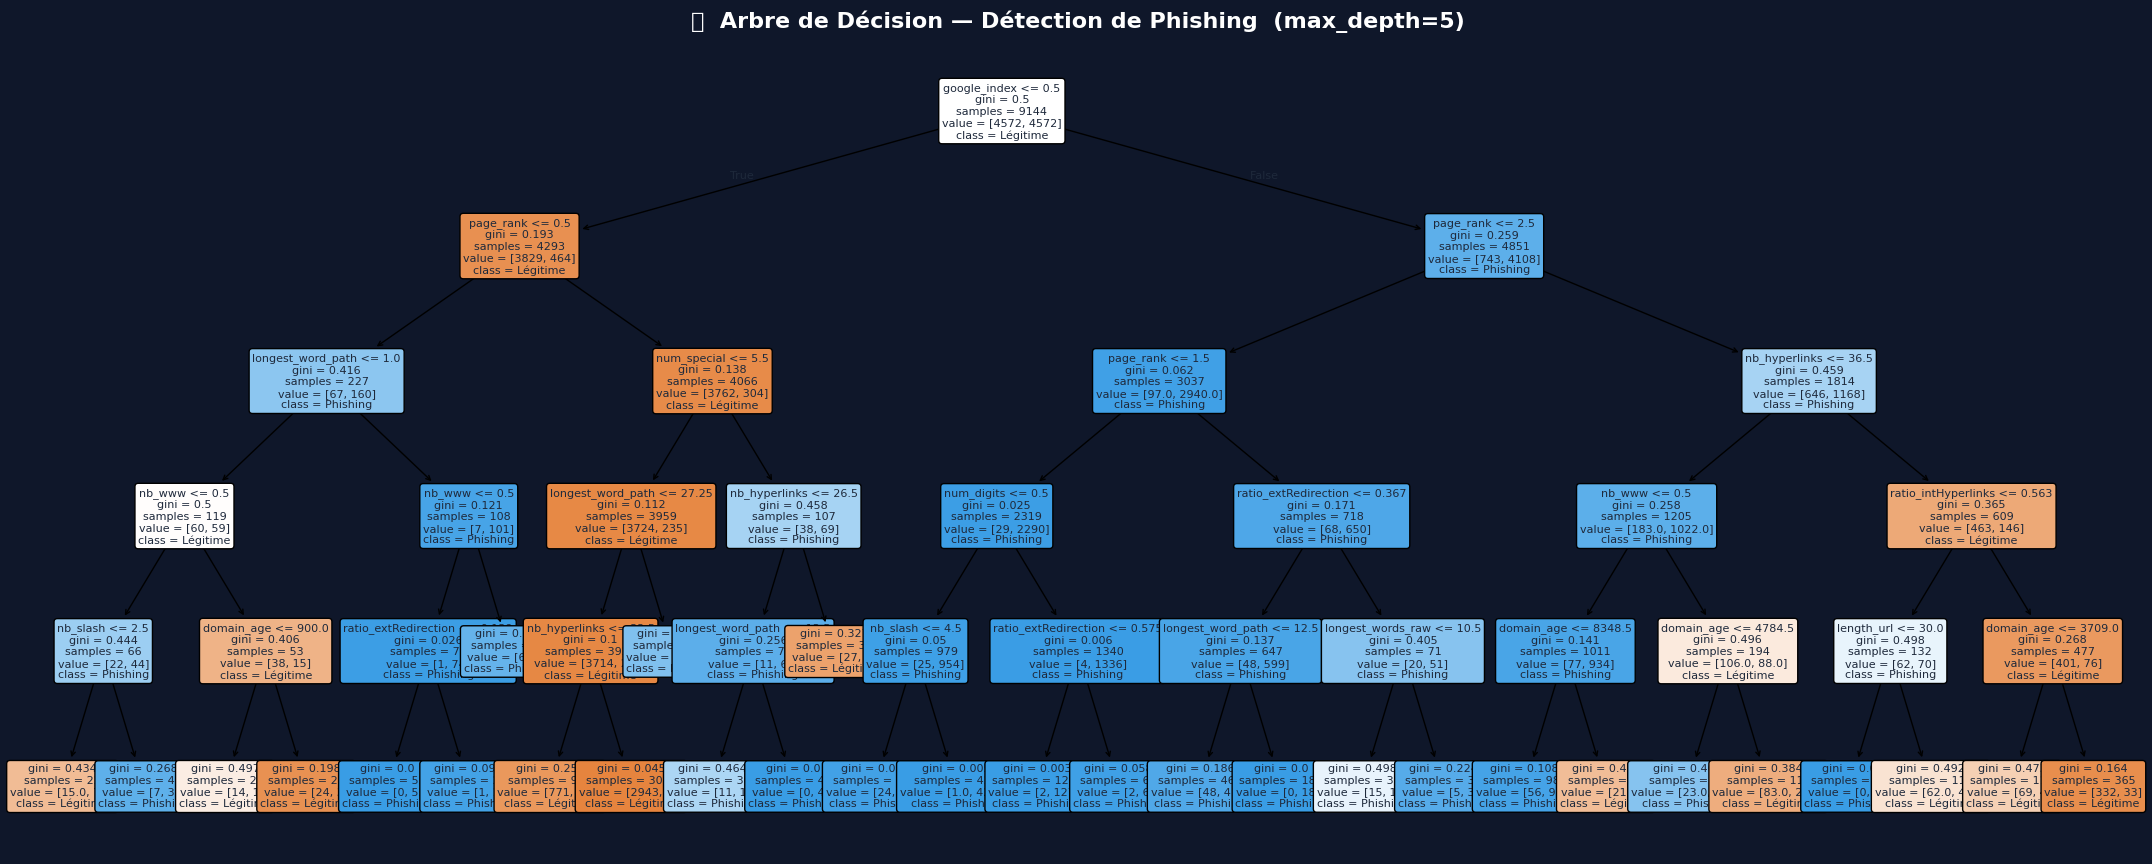

In [75]:
# 6. VISUALISATION

%matplotlib inline

fig = plt.figure(figsize=(22, 18))
fig.patch.set_facecolor('#0f172a')

#  6a. Arbre de décision
ax_tree = fig.add_axes([0.02, 0.52, 0.96, 0.45])
ax_tree.set_facecolor('#0f172a')

plot_tree(
    clf,
    feature_names = feature_names,
    class_names   = class_names,
    filled        = True,
    rounded       = True,
    fontsize      = 8,
    ax            = ax_tree,
    impurity      = True,
    precision     = 3,
)
for text in ax_tree.texts:
    text.set_color('#1e293b')

ax_tree.set_title(
    '🌳  Arbre de Décision — Détection de Phishing  (max_depth=5)',
    fontsize=16, color='white', pad=12, fontweight='bold'
)

plt.show()
plt.close()

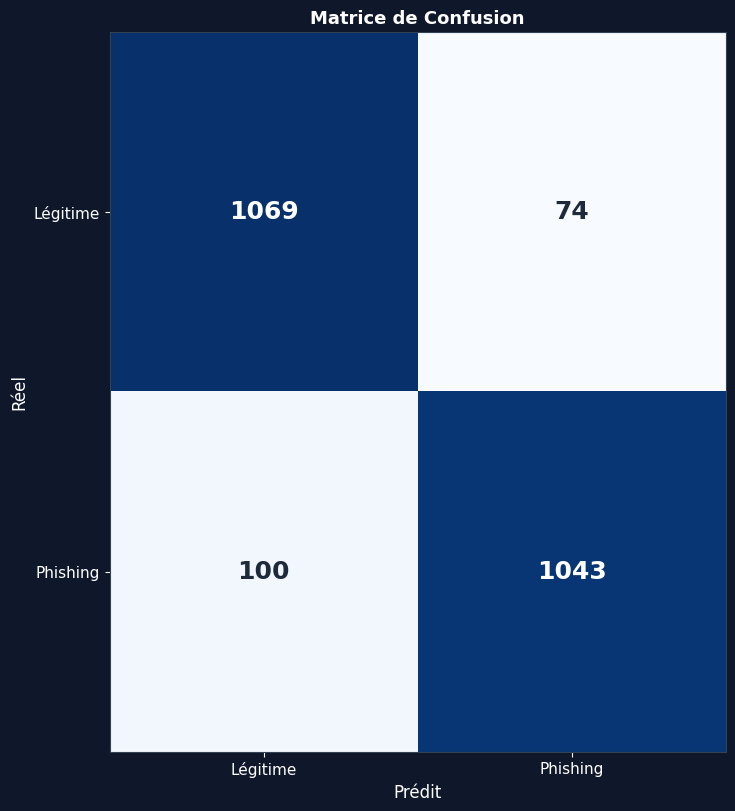

In [76]:
#  6b. Matrice de confusion

%matplotlib inline

fig = plt.figure(figsize=(22, 18))
fig.patch.set_facecolor('#0f172a')


ax_cm = fig.add_axes([0.04, 0.06, 0.28, 0.40])
ax_cm.set_facecolor('#1e293b')

ax_cm.imshow(cm, cmap='Blues', aspect='auto')
for i in range(2):
    for j in range(2):
        ax_cm.text(
            j, i, f'{cm[i,j]}',
            ha='center', va='center', fontsize=18, fontweight='bold',
            color='white' if cm[i,j] > cm.max() / 2 else '#1e293b'
        )

ax_cm.set_xticks([0, 1]); ax_cm.set_yticks([0, 1])
ax_cm.set_xticklabels(['Légitime', 'Phishing'], color='white', fontsize=11)
ax_cm.set_yticklabels(['Légitime', 'Phishing'], color='white', fontsize=11)
ax_cm.set_xlabel('Prédit', color='white', fontsize=12)
ax_cm.set_ylabel('Réel',   color='white', fontsize=12)
ax_cm.set_title('Matrice de Confusion', color='white', fontsize=13, fontweight='bold')
ax_cm.tick_params(colors='white')
for spine in ax_cm.spines.values():
    spine.set_edgecolor('#334155')

plt.show()
plt.close()

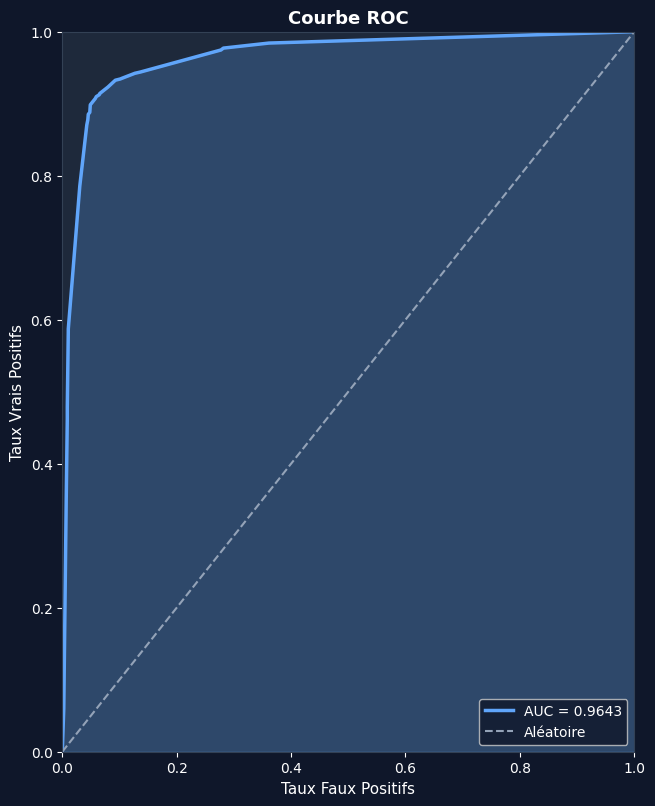

In [77]:
#6c. Courbe ROC

%matplotlib inline

fig = plt.figure(figsize=(22, 18))
fig.patch.set_facecolor('#0f172a')


ax_roc = fig.add_axes([0.38, 0.06, 0.26, 0.40])
ax_roc.set_facecolor('#1e293b')

fpr, tpr, _ = roc_curve(y_test, y_proba)
ax_roc.fill_between(fpr, tpr, alpha=0.25, color='#60a5fa')
ax_roc.plot(fpr, tpr, color='#60a5fa', lw=2.5, label=f'AUC = {auc:.4f}')
ax_roc.plot([0, 1], [0, 1], '--', color='#94a3b8', lw=1.5, label='Aléatoire')
ax_roc.set_xlabel('Taux Faux Positifs', color='white', fontsize=11)
ax_roc.set_ylabel('Taux Vrais Positifs', color='white', fontsize=11)
ax_roc.set_title('Courbe ROC', color='white', fontsize=13, fontweight='bold')
ax_roc.tick_params(colors='white')
ax_roc.legend(facecolor='#0f172a', labelcolor='white', fontsize=10)
for spine in ax_roc.spines.values():
    spine.set_edgecolor('#334155')
ax_roc.set_xlim(0, 1); ax_roc.set_ylim(0, 1)



plt.show()
plt.close()


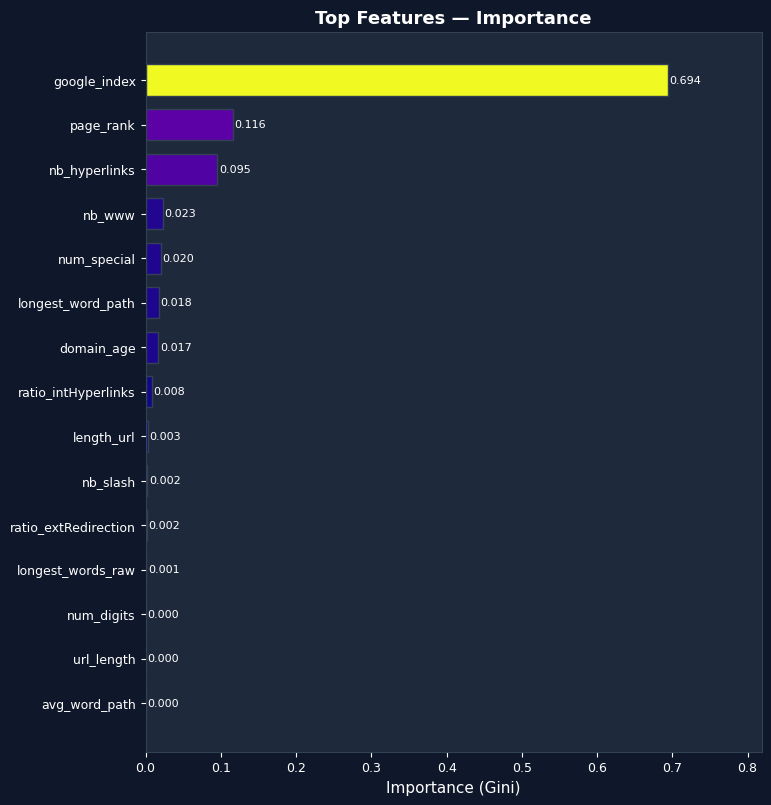

In [104]:
# ── 6d. Importance des features

%matplotlib inline

fig = plt.figure(figsize=(22, 18))
fig.patch.set_facecolor('#0f172a')


ax_fi = fig.add_axes([0.70, 0.06, 0.28, 0.40])
ax_fi.set_facecolor('#1e293b')

importances = clf.feature_importances_
idx         = np.argsort(importances)[-15:]          # top 15 features
colors_bar  = plt.cm.plasma(importances[idx] / importances[idx].max())
bars = ax_fi.barh(
    np.array(feature_names)[idx], importances[idx],
    color=colors_bar, edgecolor='#334155', height=0.7
)
for bar, val in zip(bars, importances[idx]):
    ax_fi.text(
        val + 0.002, bar.get_y() + bar.get_height() / 2,
        f'{val:.3f}', va='center', color='white', fontsize=8
    )

ax_fi.set_xlabel('Importance (Gini)', color='white', fontsize=11)
ax_fi.set_title('Top Features — Importance', color='white', fontsize=13, fontweight='bold')
ax_fi.tick_params(colors='white', labelsize=9)
ax_fi.set_xlim(0, importances[idx].max() * 1.18)
for spine in ax_fi.spines.values():
    spine.set_edgecolor('#334155')


plt.show()
plt.close()

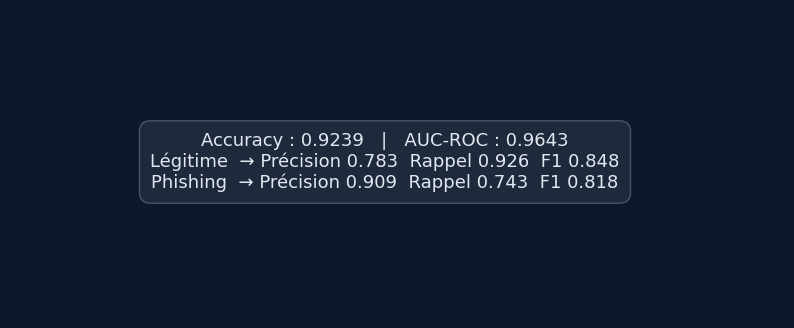

In [106]:
# ── Bandeau métriques

%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor('#0f172a')
ax.axis('off')

metrics_text = (
    f"Accuracy : {acc:.4f}   |   AUC-ROC : {auc:.4f}\n"
    f"Légitime  → Précision {p0:.3f}  Rappel {r0:.3f}  F1 {f0:.3f}\n"
    f"Phishing  → Précision {p1:.3f}  Rappel {r1:.3f}  F1 {f1_:.3f}"
)

fig.text(
    0.5, 0.5, metrics_text,
    ha='center', va='center',
    color='#e2e8f0', fontsize=13,
    bbox=dict(facecolor='#1e293b', edgecolor='#475569',
              boxstyle='round,pad=0.6')
)

plt.show()


# **Naive Bayes**

In [84]:
# --- 1. IMPORTS ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score, roc_curve
)

In [85]:
# --- 2. CHARGEMENT DES DONNÉES ---

from google.colab import files
uploaded = files.upload()
df = pd.read_csv('Phishing.csv')



print("Shape:", df.shape)
print("\nDistribution de la cible:")
print(df['status'].value_counts())
print("\nValeurs nulles:", df.isnull().sum().sum())

Saving Phishing.csv to Phishing (4).csv
Shape: (11430, 21)

Distribution de la cible:
status
0    5715
1    5715
Name: count, dtype: int64

Valeurs nulles: 0


In [86]:
# --- 3. SÉPARATION FEATURES / CIBLE ---
X = df.drop('status', axis=1)
y = df['status']

print("\nFeatures utilisées:", X.columns.tolist())


Features utilisées: ['length_url', 'length_hostname', 'nb_dots', 'nb_slash', 'nb_www', 'length_words_raw', 'shortest_word_host', 'longest_words_raw', 'longest_word_path', 'avg_word_path', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_extRedirection', 'domain_registration_length', 'domain_age', 'google_index', 'page_rank', 'url_length', 'num_digits', 'num_special']


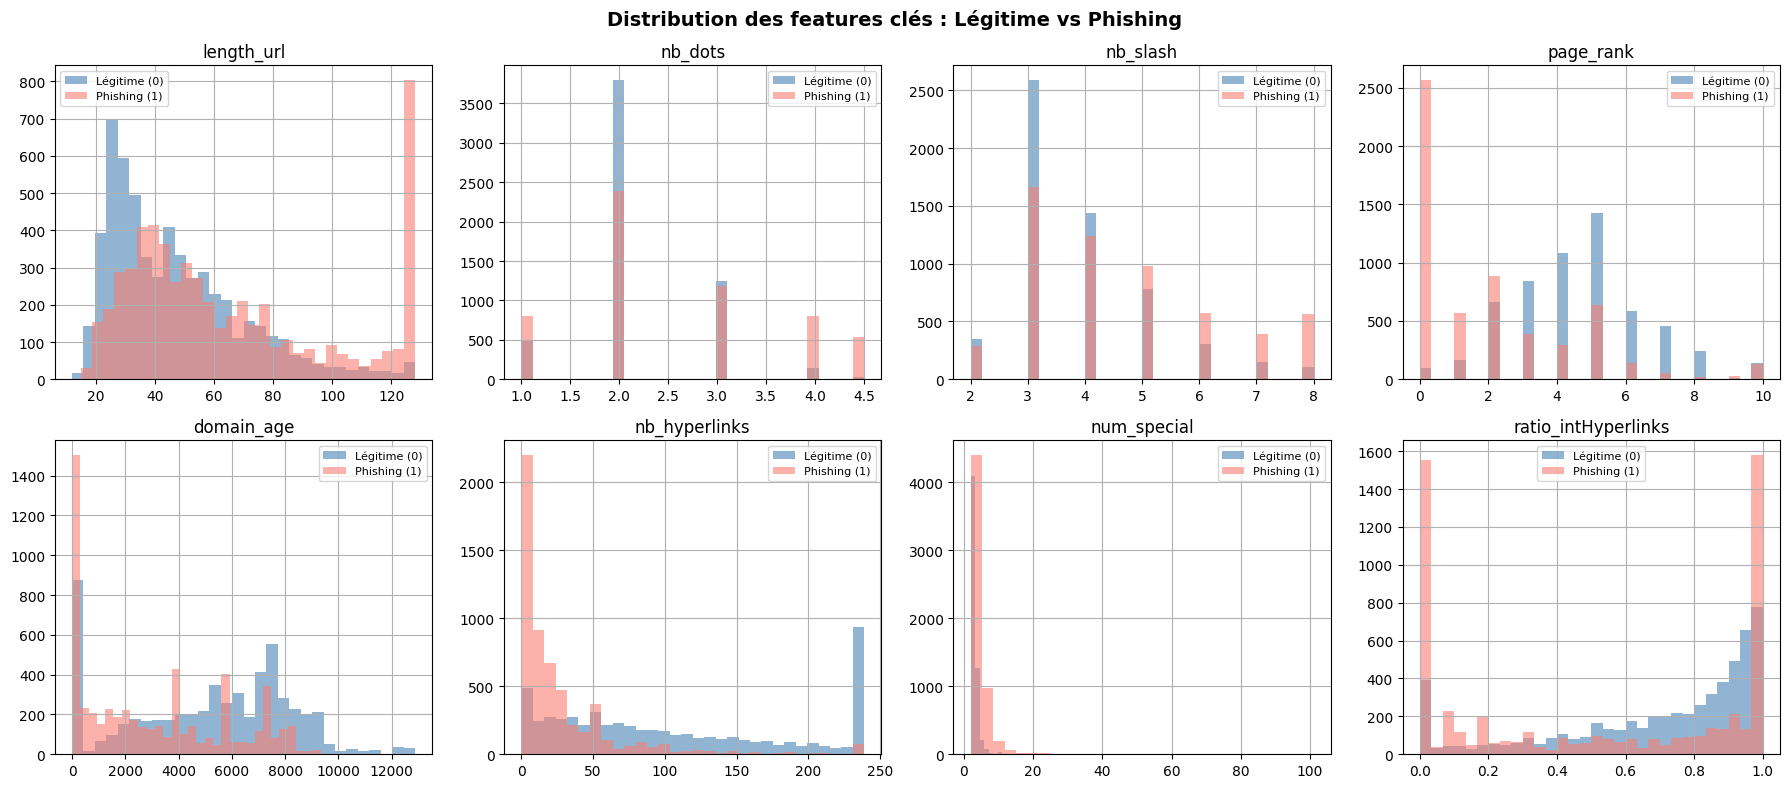

In [89]:
# --- 4. ANALYSE EXPLORATOIRE SUPPLÉMENTAIRE ---
# Comparaison des features clés entre phishing et légitime
key_features = ['length_url', 'nb_dots', 'nb_slash', 'page_rank',
                'domain_age', 'nb_hyperlinks', 'num_special', 'ratio_intHyperlinks']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Distribution des features clés : Légitime vs Phishing', fontsize=14, fontweight='bold')

for i, feature in enumerate(key_features):
    ax = axes[i // 4][i % 4]
    df[df['status'] == 0][feature].hist(ax=ax, alpha=0.6, bins=30,
                                         label='Légitime (0)', color='steelblue')
    df[df['status'] == 1][feature].hist(ax=ax, alpha=0.6, bins=30,
                                         label='Phishing (1)', color='salmon')
    ax.set_title(feature)
    ax.legend(fontsize=8)
    ax.set_xlabel('')

plt.tight_layout()
plt.savefig('distribution_features.png', dpi=150, bbox_inches='tight')
plt.show()



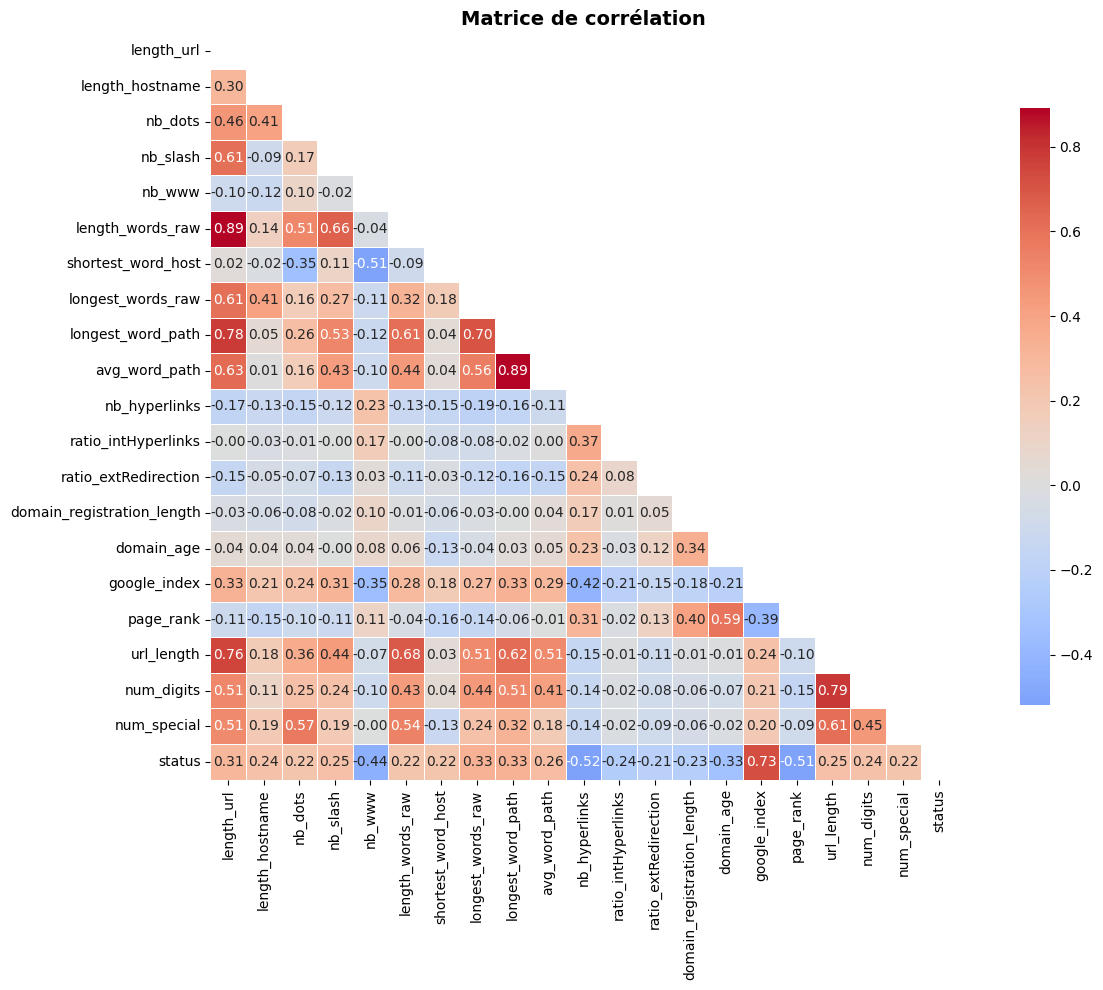

In [88]:
# Correlation heatmap
plt.figure(figsize=(14, 10))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": .8})
plt.title('Matrice de corrélation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [90]:
# --- 5. SPLIT TRAIN / TEST ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 80% entraînement, 20% test
    random_state=42,      # reproductibilité
    stratify=y            # garde l'équilibre 50/50 dans les deux ensembles
)

print(f"\nTrain set: {X_train.shape[0]} exemples")
print(f"Test set : {X_test.shape[0]} exemples")


Train set: 9144 exemples
Test set : 2286 exemples


In [92]:
# --- 6. ENTRAÎNEMENT DU MODÈLE NAIVE BAYES ---
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

print("\n✅ Modèle Naive Bayes entraîné avec succès !")


✅ Modèle Naive Bayes entraîné avec succès !


In [93]:
# --- 7. PRÉDICTIONS ---
y_pred = nb_model.predict(X_test)
y_prob = nb_model.predict_proba(X_test)[:, 1]  # probabilité d'être phishing

In [94]:
# --- 8. ÉVALUATION DES PERFORMANCES ---
print("\n" + "="*55)
print("         RÉSULTATS DU MODÈLE NAIVE BAYES")
print("="*55)

accuracy = accuracy_score(y_test, y_pred)
roc_auc  = roc_auc_score(y_test, y_prob)

print(f"\n📊 Accuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"📊 ROC-AUC   : {roc_auc:.4f}")

print("\n📋 Rapport de classification :")
print(classification_report(y_test, y_pred,
      target_names=['Légitime (0)', 'Phishing (1)']))


         RÉSULTATS DU MODÈLE NAIVE BAYES

📊 Accuracy  : 0.8342 (83.42%)
📊 ROC-AUC   : 0.9398

📋 Rapport de classification :
              precision    recall  f1-score   support

Légitime (0)       0.78      0.93      0.85      1143
Phishing (1)       0.91      0.74      0.82      1143

    accuracy                           0.83      2286
   macro avg       0.85      0.83      0.83      2286
weighted avg       0.85      0.83      0.83      2286



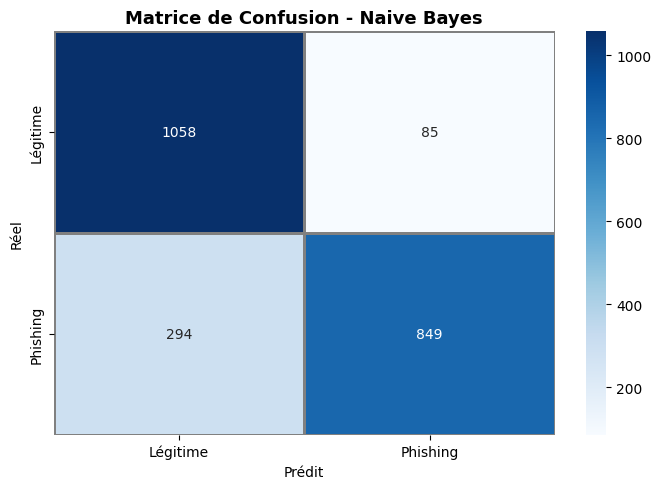


  Vrais Négatifs (TN) : 1058  → Légitimes bien classifiés
  Faux Positifs  (FP) : 85  → Légitimes classifiés phishing (fausse alarme)
  Faux Négatifs  (FN) : 294  → Phishing classifiés légitimes (dangereux !)
  Vrais Positifs (TP) : 849  → Phishing bien détectés


In [95]:
# --- 9. MATRICE DE CONFUSION ---
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Légitime', 'Phishing'],
            yticklabels=['Légitime', 'Phishing'],
            linewidths=1, linecolor='gray')
plt.title('Matrice de Confusion - Naive Bayes', fontsize=13, fontweight='bold')
plt.ylabel('Réel')
plt.xlabel('Prédit')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Lecture rapide de la matrice
tn, fp, fn, tp = cm.ravel()
print(f"\n  Vrais Négatifs (TN) : {tn}  → Légitimes bien classifiés")
print(f"  Faux Positifs  (FP) : {fp}  → Légitimes classifiés phishing (fausse alarme)")
print(f"  Faux Négatifs  (FN) : {fn}  → Phishing classifiés légitimes (dangereux !)")
print(f"  Vrais Positifs (TP) : {tp}  → Phishing bien détectés")


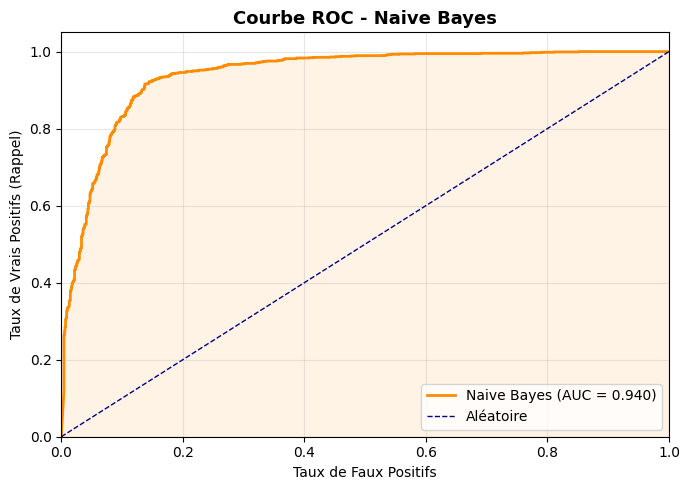

In [96]:
# --- 10. COURBE ROC ---
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Naive Bayes (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Aléatoire')
plt.fill_between(fpr, tpr, alpha=0.1, color='darkorange')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs')
plt.ylabel('Taux de Vrais Positifs (Rappel)')
plt.title('Courbe ROC - Naive Bayes', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()


In [97]:
# --- 11. CROSS-VALIDATION (validation croisée) ---
print("\n📊 Validation croisée (5-Fold Stratified) :")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(GaussianNB(), X, y, cv=skf, scoring='accuracy')

print(f"  Scores par fold : {[f'{s:.4f}' for s in cv_scores]}")
print(f"  Moyenne         : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")



📊 Validation croisée (5-Fold Stratified) :
  Scores par fold : ['0.8430', '0.8403', '0.8233', '0.8307', '0.8451']
  Moyenne         : 0.8365 ± 0.0082



📊 Analyse de séparabilité des features :
                   Feature    Score  Moy_Légitime  Moy_Phishing
              google_index 2.155899      0.169204      0.898688
             nb_hyperlinks 1.274405    106.185652     27.785827
                 page_rank 1.194131      4.482415      1.889064
                    nb_www 0.990622      0.671041      0.225897
         longest_words_raw 0.722884     10.907262     14.847332
         longest_word_path 0.720576      5.600262     10.767804
                domain_age 0.704896   5094.089939   3031.330534
                length_url 0.657084     46.887839     65.767804
                num_digits 0.560120      1.528609      9.375678
                url_length 0.559057     47.381452     74.858618
             avg_word_path 0.553759      3.662558      5.781959
                  nb_slash 0.519680      3.819073      4.587052
       ratio_intHyperlinks 0.510694      0.694306      0.510608
           length_hostname 0.508889     18.498425     22.10726

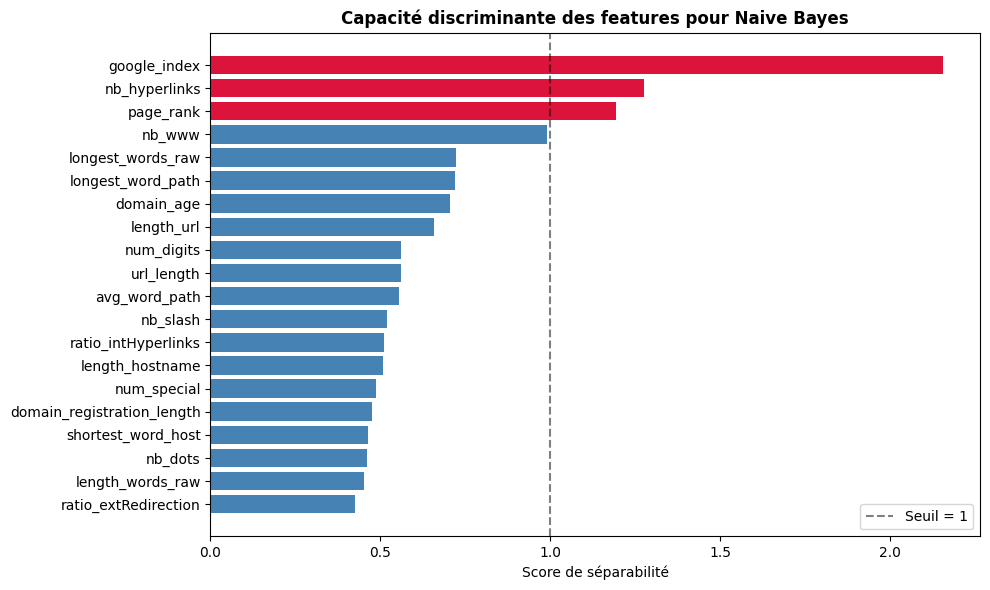

In [99]:
 #--- 12. IMPORTANCE DES FEATURES (approche Naive Bayes) ---
# Pour GaussianNB, on compare les moyennes par classe
print("\n📊 Analyse de séparabilité des features :")
feature_importance = []
for col in X.columns:
    mean_legit   = df[df['status'] == 0][col].mean()
    mean_phish   = df[df['status'] == 1][col].mean()
    std_legit    = df[df['status'] == 0][col].std()
    std_phish    = df[df['status'] == 1][col].std()
    # Ratio de séparabilité (inspiré de Fisher)
    diff = abs(mean_phish - mean_legit)
    avg_std = (std_legit + std_phish) / 2 + 1e-9
    score = diff / avg_std
    feature_importance.append({'Feature': col, 'Score': score,
                                'Moy_Légitime': mean_legit, 'Moy_Phishing': mean_phish})

fi_df = pd.DataFrame(feature_importance).sort_values('Score', ascending=False)
print(fi_df.to_string(index=False))

# Visualisation
plt.figure(figsize=(10, 6))
colors = ['crimson' if s > 1 else 'steelblue' for s in fi_df['Score']]
plt.barh(fi_df['Feature'], fi_df['Score'], color=colors)
plt.xlabel('Score de séparabilité')
plt.title('Capacité discriminante des features pour Naive Bayes', fontsize=12, fontweight='bold')
plt.axvline(x=1, color='black', linestyle='--', alpha=0.5, label='Seuil = 1')
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [100]:
# --- 13. TEST SUR UN EXEMPLE FICTIF ---
print("\n🔍 Test sur un exemple fictif :")
# Une URL suspecte (longue, beaucoup de caractères spéciaux, page_rank faible)
exemple_suspect = pd.DataFrame([{
    'length_url': 120, 'length_hostname': 35, 'nb_dots': 5,
    'nb_slash': 8, 'nb_www': 2, 'length_words_raw': 200,
    'shortest_word_host': 3, 'longest_words_raw': 40,
    'longest_word_path': 35, 'avg_word_path': 20,
    'nb_hyperlinks': 50, 'ratio_intHyperlinks': 0.1,
    'ratio_extRedirection': 0.8, 'domain_registration_length': 30,
    'domain_age': 5, 'google_index': 0, 'page_rank': 1,
    'url_length': 120, 'num_digits': 15, 'num_special': 20
}])

prediction  = nb_model.predict(exemple_suspect)[0]
probabilite = nb_model.predict_proba(exemple_suspect)[0]

print(f"  Prédiction  : {'🚨 PHISHING' if prediction == 1 else '✅ LÉGITIME'}")
print(f"  Probabilité : Légitime={probabilite[0]:.3f} | Phishing={probabilite[1]:.3f}")


🔍 Test sur un exemple fictif :
  Prédiction  : 🚨 PHISHING
  Probabilité : Légitime=0.000 | Phishing=1.000
